In [1]:
# Step 1
import numpy as np
import CoolProp.CoolProp as CP

In [2]:
# Step 2
# =====================================================================
# Full lunar day-night cycle: solar tower -> regolith TES -> sCO2 (simple + recuperated)
# Quasi-steady model following Prasad et al. (Table 2, Table 3, Appendix A)
# Day:   solar heat charges the TES; the cycle runs from the TES
# Night: the cycle runs from the TES only
# The turbine inlet always follows the TES: TIT = T_TES - dT_PHX
# =====================================================================

# --- Lunar day / night timing ---
t_lunar = 29.53 * 24       # h, synodic lunar day-night cycle
t_night = t_lunar / 2      # h, lunar night duration
t_day = t_lunar - t_night  # h, lunar daytime
dt = 1.0                   # h, time step
n_day = int(round(t_day / dt))
n_night = int(round(t_night / dt))
n_cycle = n_day + n_night
# snap durations to whole time steps so sunrise/sunset fall on a step
t_day, t_night, t_lunar = n_day * dt, n_night * dt, n_cycle * dt

# --- Electrical demand (same day and night) ---
W_elec_target = 100.0      # kWe, habitat electrical demand (Table 2: 75-150 kWe)
eta_gen = 0.95             # generator efficiency (Table 2)

# --- Plant self-use (parasitic loads), on top of the habitat demand ---
# Assumed values (no lunar data): run as a sensitivity study
W_aux_fixed = 3.0          # kWe, controls, sensors, power electronics (always)
f_aux_heat = 0.01          # kWe per kW of Q_in, moving heat out of the regolith
f_aux_rad = 0.01           # kWe per kW of Q_rad, radiator loop pump
W_aux_day = 2.0            # kWe, heliostat drives (day only)
# The shaft power the cycle must deliver is no longer a constant: it is
# (W_elec_target + parasitic loads) / eta_gen, solved each hour in Step 6.
W_net_target = W_elec_target / eta_gen   # kW, shaft power for the habitat alone (reference only)

# --- TES (regolith) ---
T_TES_max = 1000.0          # K, fully charged  
T_TES_min = 450.0          # K, lower limit   
rho_TES = 1500.0           # kg/m3, regolith bulk density (Table 3)
regolith_type = 'highlands'   # 'high_Ti_mare', 'low_Ti_mare', 'highlands'
TES_mass_margin = 1.20     # TES mass = margin x minimum mass for the night alone

# --- Solar tower / CSP ---
G_sun = 1361.0             # W/m2, solar irradiance at the Moon
eta_opt = 0.75             # optical efficiency (heliostats/concentrator)

# Receiver (replaces a fixed receiver efficiency): absorbs alpha_rec of the
# concentrated light and radiates eps_rec*sigma*T_rec^4 from its aperture.
alpha_rec = 0.95           # receiver absorptance
eps_rec = 0.90             # receiver emissivity (aperture radiation loss)
C_ratio = 200.0            # concentration ratio = collector area / receiver aperture area
dT_rec = 10.0              # K, receiver runs this much hotter than the TES (to charge it)
latitude_deg = 0.0         # site latitude (0 = equator)
collector_mode = 'fixed'   # 'fixed': flux x sin(sun elevation) (incidence angle)
                           # 'tracking': full flux whenever the sun is up
n_cycles_periodic = 4      # lunar cycles simulated to reach a repeating state

# --- sCO2 Brayton cycle (Table 2) ---
FLUID = 'CO2'
T_comp_in = 320.0          # K, compressor inlet temperature (305-320 K)
P_low = 8.5e6              # Pa, compressor inlet pressure (7.5-8.0 MPa)
P_high = 20.0e6            # Pa, turbine inlet pressure (20-20 MPa)
eta_comp = 0.80            # compressor isentropic efficiency
eta_turb = 0.85            # turbine isentropic efficiency
dT_PHX = 10.0              # K, primary HX approach: TIT = T_TES - dT_PHX
eta_cycle_min = 0.05       # cycle is shut down below this efficiency

# --- Cycle configurations (Section IV): both are calculated every run ---
cycles = ['simple', 'recuperated']
eps_recup = 0.85           # recuperator effectiveness (Table 2)

# Turbine inlet limit follows the TES automatically -- do not set by hand
TIT_max = T_TES_max - dT_PHX

# --- Waste-heat recovery and radiator (Table 2) ---
eta_rec = 0.5              # waste-heat recovery fraction to habitat (0-1)
T_rad = 300.0              # K, radiator surface temperature (must be < T_comp_in)
emissivity = 0.85          # radiator emissivity (0.6-0.9)
sigma = 5.670374419e-8     # W/m2-K4

# --- Radiator environment (varies with the sun angle, see Step 8) ---
T_surf_night = 100.0       # K, lunar surface at night
T_surf_noon = 392.0        # K, lunar surface at noon (equator)
T_space = 3.0              # K, deep space
F_rad_surf = 0.5           # radiator view factor to the lunar surface (vertical panel)
shield = False             # True: radiator shaded from the surface (sees space only)
_F = 0.0 if shield else F_rad_surf
T_sink_night = (_F * T_surf_night**4 + (1 - _F) * T_space**4) ** 0.25   # K, night sink

# --- Input checks: stop with a clear message if inputs are inconsistent ---
T_crit, P_crit = 304.13, 7.3773e6     # CO2 critical point
assert T_comp_in > T_crit, f"T_comp_in must be above CO2 critical temperature ({T_crit} K)"
assert P_low > P_crit, f"P_low must be above CO2 critical pressure ({P_crit/1e6:.2f} MPa)"
assert P_high > P_low, "P_high must be greater than P_low"
assert T_TES_max > T_TES_min, "T_TES_max must be greater than T_TES_min"
assert T_TES_min >= 350, "Regolith cp correlation (Table 3, T > 350 K) needs T_TES_min >= 350 K"
assert TIT_max > T_comp_in + 30, "TES too cold: turbine inlet would be below the compressor range"
assert T_rad < T_comp_in, "Radiator must be colder than the compressor inlet to cool the CO2"
assert T_rad > T_sink_night, "Radiator must be hotter than the night sink"
assert 0 <= F_rad_surf <= 1, "F_rad_surf must be between 0 and 1"
assert 0 <= eta_rec <= 1, "eta_rec must be between 0 and 1"
assert 0 < eta_comp <= 1 and 0 < eta_turb <= 1 and 0 < eta_gen <= 1, "Efficiencies must be in (0, 1]"
assert 0 < t_night < t_lunar, "t_night must be shorter than the lunar cycle"
assert collector_mode in ('fixed', 'tracking'), "collector_mode must be 'fixed' or 'tracking'"
assert TES_mass_margin > 1.0, "TES_mass_margin must be > 1 so the TES survives dawn and dusk"
assert 0 <= eps_recup < 1, "eps_recup must be in [0, 1)"
assert 0 < alpha_rec <= 1 and 0 < eps_rec <= 1, "Receiver absorptance/emissivity must be in (0, 1]"
assert C_ratio > 1, "C_ratio must be > 1"
assert W_aux_fixed >= 0 and W_aux_day >= 0, "Fixed parasitic loads must be >= 0"
assert 0 <= f_aux_heat < 0.2 and 0 <= f_aux_rad < 0.2, "Parasitic fractions must be in [0, 0.2)"

print(f"Inputs OK: cycles {cycles}, TES {T_TES_max:.0f} -> {T_TES_min:.0f} K, TIT max {TIT_max:.0f} K, "
      f"PR {P_high/P_low:.2f}, {W_elec_target:.0f} kWe + parasitic ({W_aux_fixed:.0f} kWe fixed, "
      f"{W_aux_day:.0f} kWe day), day {t_day:.0f} h / night {t_night:.0f} h")

Inputs OK: cycles ['simple', 'recuperated'], TES 1000 -> 450 K, TIT max 990 K, PR 2.35, 100 kWe + parasitic (3 kWe fixed, 2 kWe day), day 354 h / night 354 h


In [3]:
# Step 3
# ---------------------------------------------------------------------
# Regolith specific heat (Table 3, Schreiner et al. 2016)
# For T > 350 K: cp = Cf + Cg*T + Ch/T^2   [J/kg-K]
# (The 100-350 K polynomial in Table 3 gives J/g-K, not J/kg-K;
#  it is not needed here because the TES stays at or above 350 K.)
# ---------------------------------------------------------------------
REGOLITH_CP = {
    'high_Ti_mare': (8.820e2, 3.083e-1, -2.278e7),
    'low_Ti_mare':  (9.093e2, 2.870e-1, -2.469e7),
    'highlands':    (9.530e2, 2.524e-1, -2.645e7),
}
Cf, Cg, Ch = REGOLITH_CP[regolith_type]

def cp_regolith(T):
    return Cf + Cg * T - (-Ch) / T**2      # J/kg-K  (Ch is negative)

def e_regolith(T):
    """Specific sensible energy relative to T_TES_min, J/kg (integral of cp dT)."""
    F = lambda T: Cf * T + 0.5 * Cg * T**2 - Ch / T
    return F(T) - F(T_TES_min)

# Lookup table for inverting energy -> temperature
T_grid_TES = np.linspace(T_TES_min - 50, T_TES_max + 1, 4000)
e_grid_TES = e_regolith(T_grid_TES)

def T_from_e(e):
    return np.interp(e, e_grid_TES, T_grid_TES)

In [4]:
# Step 4
# ---------------------------------------------------------------------
# Simple sCO2 Brayton cycle (Appendix Table A, Eq. 1-10)
# States: 1 compressor in, 2 compressor out / PHX in,
#         3 PHX out / turbine in, 4 turbine out / cooler in
# Results for each cycle are stored in CYC[cycle] (grid, cutoff), and
# cycle_at(TIT, ct) reads them. Step 4b adds the recuperated cycle.
# ---------------------------------------------------------------------
def simple_cycle(TIT):
    h1 = CP.PropsSI('H', 'T', T_comp_in, 'P', P_low, FLUID)
    s1 = CP.PropsSI('S', 'T', T_comp_in, 'P', P_low, FLUID)
    h2s = CP.PropsSI('H', 'S', s1, 'P', P_high, FLUID)
    h2 = h1 + (h2s - h1) / eta_comp                      # Eq. 8
    h3 = CP.PropsSI('H', 'T', TIT, 'P', P_high, FLUID)
    s3 = CP.PropsSI('S', 'T', TIT, 'P', P_high, FLUID)
    h4s = CP.PropsSI('H', 'S', s3, 'P', P_low, FLUID)
    h4 = h3 - eta_turb * (h3 - h4s)                      # Eq. 10

    w_c = h2 - h1                 # Eq. 1 (per kg)
    q_in = h3 - h2                # Eq. 2
    w_t = h3 - h4                 # Eq. 3
    q_out = h4 - h1               # Eq. 4
    w_net = w_t - w_c             # Eq. 5
    eta = w_net / q_in            # Eq. 6
    T2 = CP.PropsSI('T', 'H', h2, 'P', P_high, FLUID)
    T4 = CP.PropsSI('T', 'H', h4, 'P', P_low, FLUID)
    return dict(eta=eta, w_net=w_net, w_c=w_c, w_t=w_t, q_in=q_in, q_out=q_out,
                q_rec=0.0, T2=T2, T4=T4, T_cool_in=T4, h1=h1, h2=h2, h3=h3, h4=h4)

def build_cycle_table(cycle_fn):
    """Pre-compute a cycle on the TIT grid and find its TIT / TES cutoff."""
    rows = [cycle_fn(T) for T in TIT_grid]
    G = {k: np.array([r[k] for r in rows]) for k in rows[0]}
    # Lowest TIT at which the cycle still produces net work at the minimum
    # efficiency (scan down from TIT_max; stop at the first failure)
    ok = (G['w_net'] > 0) & (G['q_in'] > 0) & (G['eta'] >= eta_cycle_min)
    first_fail_from_top = np.argmax(~ok[::-1])
    TIT_cut = TIT_grid[len(TIT_grid) - first_fail_from_top] if not ok.all() else TIT_grid[0]
    return dict(G=G, TIT_cutoff=TIT_cut, T_TES_cutoff=max(T_TES_min, TIT_cut + dT_PHX))

def cycle_at(TIT, ct='simple'):
    G = CYC[ct]['G']
    return {k: np.interp(TIT, TIT_grid, G[k]) for k in G}

TIT_grid = np.arange(T_comp_in + 30, TIT_max + 0.5, 0.5)
CYC = {'simple': build_cycle_table(simple_cycle)}
print(f"simple cycle: eta at TIT {TIT_max:.0f} K = {cycle_at(TIT_max, 'simple')['eta']*100:.2f} %, "
      f"usable TES down to {CYC['simple']['T_TES_cutoff']:.0f} K")

simple cycle: eta at TIT 990 K = 11.43 %, usable TES down to 466 K


In [6]:
# Step 6
# ---------------------------------------------------------------------
# Recuperated sCO2 Brayton cycle (Appendix Table A, Eq. 11-20)
# States: 1 compressor in        2 compressor out / recuperator cold in
#         3 recuperator cold out / PHX in      4 PHX out / turbine in (TIT)
#         5 turbine out / recuperator hot in   6 recuperator hot out / cooler in
# Recuperator duty = eps_recup x the largest possible duty (limited by the
# stream that can change least), so neither stream crosses the other's inlet T.
# ---------------------------------------------------------------------
def recuperated_cycle(TIT):
    h1 = CP.PropsSI('H', 'T', T_comp_in, 'P', P_low, FLUID)
    s1 = CP.PropsSI('S', 'T', T_comp_in, 'P', P_low, FLUID)
    h2s = CP.PropsSI('H', 'S', s1, 'P', P_high, FLUID)
    h2 = h1 + (h2s - h1) / eta_comp                      # Eq. 8
    T2 = CP.PropsSI('T', 'H', h2, 'P', P_high, FLUID)
    h4 = CP.PropsSI('H', 'T', TIT, 'P', P_high, FLUID)
    s4 = CP.PropsSI('S', 'T', TIT, 'P', P_high, FLUID)
    h5s = CP.PropsSI('H', 'S', s4, 'P', P_low, FLUID)
    h5 = h4 - eta_turb * (h4 - h5s)                      # Eq. 10
    T5 = CP.PropsSI('T', 'H', h5, 'P', P_low, FLUID)

    # Recuperator (Eq. 11-14)
    dh_hot_max = h5 - CP.PropsSI('H', 'T', T2, 'P', P_low, FLUID)    # hot side cooled to T2
    dh_cold_max = CP.PropsSI('H', 'T', T5, 'P', P_high, FLUID) - h2  # cold side heated to T5
    q_rec = eps_recup * max(min(dh_hot_max, dh_cold_max), 0.0)       # Eq. 13: Q_cold = Q_hot
    h3 = h2 + q_rec                                      # Eq. 11
    h6 = h5 - q_rec                                      # Eq. 12
    T3 = CP.PropsSI('T', 'H', h3, 'P', P_high, FLUID)
    T6 = CP.PropsSI('T', 'H', h6, 'P', P_low, FLUID)

    w_c = h2 - h1                 # Eq. 17 (per kg)
    q_in = h4 - h3                # Eq. 15: heat from TES after recuperation
    w_t = h4 - h5                 # Eq. 16
    q_out = h6 - h1               # Eq. 20: heat rejected after recuperation
    w_net = w_t - w_c             # Eq. 18
    eta = w_net / q_in            # Eq. 19
    return dict(eta=eta, w_net=w_net, w_c=w_c, w_t=w_t, q_in=q_in, q_out=q_out,
                q_rec=q_rec, T2=T2, T3=T3, T5=T5, T6=T6, T_cool_in=T6,
                h1=h1, h2=h2, h3=h3, h4=h4, h5=h5, h6=h6)

def cycle_state_table(TIT, ct):
    """Cycle results and (name, T, P) of every state, for the report."""
    if ct == 'recuperated':
        r = recuperated_cycle(TIT)
        return r, [('1  Compressor inlet', T_comp_in, P_low),
                   ('2  Compressor outlet', r['T2'], P_high),
                   ('3  Recuperator cold out', r['T3'], P_high),
                   ('4  Turbine inlet', TIT, P_high),
                   ('5  Turbine outlet', r['T5'], P_low),
                   ('6  Cooler inlet', r['T6'], P_low)]
    r = simple_cycle(TIT)
    return r, [('1  Compressor inlet', T_comp_in, P_low),
               ('2  Compressor outlet', r['T2'], P_high),
               ('3  Turbine inlet', TIT, P_high),
               ('4  Turbine outlet', r['T4'], P_low)]

CYC['recuperated'] = build_cycle_table(recuperated_cycle)
print(f"recuperated cycle: eta at TIT {TIT_max:.0f} K = {cycle_at(TIT_max, 'recuperated')['eta']*100:.2f} %, "
      f"usable TES down to {CYC['recuperated']['T_TES_cutoff']:.0f} K")

recuperated cycle: eta at TIT 990 K = 30.51 %, usable TES down to 466 K


In [7]:
# Step 7
# ---------------------------------------------------------------------
# Plant performance at one TES temperature
#   ct = 'simple' or 'recuperated'
#   t  = hours since sunrise (sets day/night loads and the radiator sink, Step 8);
#        None = night
# The cycle must cover the habitat AND the plant's own loads:
#   W_gross = W_elec_target + W_aux        (electric, at the generator)
#   W_net   = W_gross / eta_gen            (shaft power from the cycle)
#   W_aux   = W_aux_fixed + W_aux_day (day only) + f_aux_heat*Q_in + f_aux_rad*Q_rad
# Q_in and Q_rad depend on W_net, so W_net is solved directly (linear):
#   Q_in = W_net/eta,  Q_out = Q_in - W_net,  Q_rad = (1 - eta_rec) * Q_out
# ---------------------------------------------------------------------
def plant_point(T_TES, t=None, ct='simple'):
    TIT = min(T_TES - dT_PHX, TIT_max)
    c = cycle_at(TIT, ct)
    is_day = (t is not None) and (np.mod(t, t_lunar) < t_day)
    W_fix = W_aux_fixed + (W_aux_day if is_day else 0.0)            # kWe
    k = (f_aux_heat / c['eta'] + f_aux_rad * (1 - eta_rec) * (1 / c['eta'] - 1)) / eta_gen
    W_net = (W_elec_target + W_fix) / eta_gen / (1 - k)             # kW shaft
    m_dot = W_net * 1e3 / c['w_net']                      # kg/s
    Q_in = m_dot * c['q_in'] / 1e3                        # kW from TES
    Q_out = m_dot * c['q_out'] / 1e3                      # kW to cooler
    W_c = m_dot * c['w_c'] / 1e3
    W_t = m_dot * c['w_t'] / 1e3
    Q_recup = m_dot * c['q_rec'] / 1e3                    # kW recuperator duty (0 for simple)
    Q_hab = eta_rec * Q_out                               # Eq. 26
    Q_rad = Q_out - Q_hab                                 # Eq. 27
    W_aux = W_fix + f_aux_heat * Q_in + f_aux_rad * Q_rad # kWe parasitic loads
    W_gross = W_net * eta_gen                             # kWe at the generator
    T_sink = T_sink_night if t is None else float(T_sink_t(t))
    q_net = emissivity * sigma * (T_rad**4 - T_sink**4)             # W/m2 radiator can reject
    A_rad = Q_rad * 1e3 / q_net if q_net > 0 else np.inf            # Eq. 28 (inf: cannot reject)
    return dict(T_TES=T_TES, TIT=TIT, eta=c['eta'], m_dot=m_dot, Q_in=Q_in,
                Q_out=Q_out, W_c=W_c, W_t=W_t, W_net=W_net, Q_recup=Q_recup,
                W_gross=W_gross, W_aux=W_aux, W_elec=W_gross - W_aux,
                Q_hab=Q_hab, Q_rad=Q_rad, A_rad=A_rad, T_sink=T_sink,
                T_cooler_in=c['T_cool_in'])

In [8]:
# Step 8
# ---------------------------------------------------------------------
# Discrete TES discharge temperatures (Section VI.4), both cycles (night)
# ---------------------------------------------------------------------
print(f"{W_elec_target:.0f} kWe, PR = {P_high/P_low:.2f}, regolith = {regolith_type}\n")
print(f"{'':6} {'':6} {'---- Simple ----':>24}   {'-- Recuperated --':>24}")
print(f"{'T_TES':>6} {'TIT':>6} {'eta':>6} {'Q_in':>8} {'Q_rad':>8}   "
      f"{'eta':>6} {'Q_in':>8} {'Q_rad':>8}")
print(f"{'K':>6} {'K':>6} {'%':>6} {'kW':>8} {'kW':>8}   {'%':>6} {'kW':>8} {'kW':>8}")
for T in np.arange(T_TES_max, T_TES_min - 1, -25):
    cols = []
    for ct in cycles:
        if T < CYC[ct]['T_TES_cutoff']:
            cols.append(f"{'cannot run':>24}")
        else:
            p = plant_point(T, ct=ct)
            cols.append(f"{p['eta']*100:6.1f} {p['Q_in']:8.0f} {p['Q_rad']:8.0f}")
    print(f"{T:6.0f} {T - dT_PHX:6.0f} " + "   ".join(cols))
for ct in cycles:
    print(f"Usable TES window ({ct}): {T_TES_max:.0f} K down to {CYC[ct]['T_TES_cutoff']:.0f} K")

100 kWe, PR = 2.35, regolith = highlands

                      ---- Simple ----          -- Recuperated --
 T_TES    TIT    eta     Q_in    Q_rad      eta     Q_in    Q_rad
     K      K      %       kW       kW        %       kW       kW
  1000    990   11.4     1093      484     30.5      373      130
   975    965   11.5     1092      483     30.1      378      132
   950    940   11.5     1090      483     29.7      384      135
   925    915   11.5     1089      482     29.2      390      138
   900    890   11.5     1088      482     28.7      397      141
   875    865   11.5     1088      482     28.2      405      145
   850    840   11.5     1088      482     27.6      414      150
   825    815   11.5     1090      482     27.0      424      155
   800    790   11.5     1092      483     26.4      435      160
   775    765   11.4     1095      485     25.6      448      167
   750    740   11.4     1100      487     24.8      463      174
   725    715   11.3     1107     

In [9]:
# Step 9
# ---------------------------------------------------------------------
# Solar input (Section VI.2: solar-angle-based CSP model) with receiver losses
# t = hours since sunrise. Sun elevation follows the lunar day:
#   sin(elevation) = cos(latitude) * sin(pi * t / t_day)
# Per m2 of collector:
#   absorbed  = G_sun * incidence factor * eta_opt * alpha_rec   (follows the sun angle)
#   rec. loss = eps_rec * sigma * (T_rec^4 - T_space^4) / C_ratio (follows the TES temperature)
#   to TES    = absorbed - loss, never below 0 (receiver closed when it would lose heat)
# with T_rec = T_TES + dT_rec
# ---------------------------------------------------------------------
def sun_sin_elevation(t):
    t = np.mod(t, t_lunar)
    s = np.cos(np.radians(latitude_deg)) * np.sin(np.pi * t / t_day)
    return np.where(t < t_day, np.maximum(s, 0.0), 0.0)

def solar_intercepted(t):
    """Concentrated sunlight reaching the receiver, per m2 of collector, W/m2."""
    s = sun_sin_elevation(t)
    factor = s if collector_mode == 'fixed' else (s > 0).astype(float)
    return G_sun * factor * eta_opt

def receiver_loss(T_TES):
    """Radiation loss from the receiver aperture, per m2 of collector, W/m2."""
    T_r = np.asarray(T_TES, dtype=float) + dT_rec
    return eps_rec * sigma * (T_r**4 - T_space**4) / C_ratio

def solar_flux(t, T_TES=T_TES_max):
    """Net heat delivered to the TES per m2 of collector, W/m2."""
    absorbed = alpha_rec * solar_intercepted(t)
    return np.where(absorbed > 0, np.maximum(absorbed - receiver_loss(T_TES), 0.0), 0.0)

def receiver_efficiency(t, T_TES):
    """Net heat to TES / concentrated light reaching the receiver (0 when closed)."""
    q_in = solar_intercepted(t)
    return np.where(q_in > 0, solar_flux(t, T_TES) / np.where(q_in > 0, q_in, 1.0), 0.0)

# --- Radiator environment from the sun angle ---
# Lunar surface: ~T_noon * sin(elevation)^0.25 by day, T_surf_night otherwise.
# Effective sink seen by the radiator (surface + space, by view factor):
#   T_sink = (F * T_surface^4 + (1 - F) * T_space^4)^0.25
def T_surface(t):
    s = sun_sin_elevation(t)
    return np.maximum(T_surf_night, T_surf_noon * s**0.25)

def T_sink_t(t):
    F = 0.0 if shield else F_rad_surf
    return (F * T_surface(t)**4 + (1 - F) * T_space**4) ** 0.25

# --- Quick look: receiver efficiency vs sun elevation and TES temperature ---
print(f"Receiver: alpha {alpha_rec}, emissivity {eps_rec}, concentration {C_ratio:.0f}x, "
      f"T_rec = T_TES + {dT_rec:.0f} K")
print(f"{'sun elev':>9}" + "".join(f"{f'TES {T:.0f} K':>12}" for T in (T_TES_min, 650, T_TES_max)))
for el in (90, 45, 30, 15, 10, 5):
    t_el = t_day / np.pi * np.arcsin(np.sin(np.radians(el)) / np.cos(np.radians(latitude_deg)))
    print(f"{el:>8}\u00b0" + "".join(f"{float(receiver_efficiency(t_el, T))*100:>11.1f}%"
                                      for T in (T_TES_min, 650, T_TES_max)))
print(f"Radiator sink: night {T_sink_night:.0f} K, noon {float(T_sink_t(t_day/2)):.0f} K "
      f"({'shielded' if shield else f'view factor to surface {F_rad_surf}'})")

Receiver: alpha 0.95, emissivity 0.9, concentration 200x, T_rec = T_TES + 10 K
 sun elev   TES 450 K   TES 650 K  TES 1000 K
      90°       93.9%       90.3%       69.0%
      45°       93.4%       88.3%       58.2%
      30°       92.8%       85.5%       43.0%
      15°       90.7%       76.7%        0.0%
      10°       88.6%       67.7%        0.0%
       5°       82.2%       40.6%        0.0%
Radiator sink: night 84 K, noon 330 K (view factor to surface 0.5)


In [10]:
# Step 10
# ---------------------------------------------------------------------
# TES energy balance over time (day and night), for cycle ct
#   dE_TES/dt = Q_solar(t, T_TES) - Q_in(T_TES) ;  extra solar heat is
#   curtailed when the TES is full. Q_solar is net of receiver losses (Step 8).
# Q_in includes the extra heat needed to cover the parasitic loads (Step 6).
# t0 = hours since sunrise at the first step
# ---------------------------------------------------------------------
e_full = e_regolith(T_TES_max)       # J/kg at full charge

def simulate(m_TES, A_col, e_start, n_steps, t0=0.0, ct='simple'):
    keys = ['t', 'is_day', 'T_TES', 'TIT', 'eta', 'm_dot', 'Q_in', 'Q_out', 'Q_recup',
            'Q_hab', 'Q_rad', 'A_rad', 'T_sink', 'W_elec', 'E_TES', 'Q_solar', 'Q_curtail',
            'Q_sun_in', 'Q_rec_loss', 'eta_rec_t', 'W_net', 'W_gross', 'W_aux']
    out = {k: [] for k in keys}
    T_cut = CYC[ct]['T_TES_cutoff']
    e = e_start
    survived = True
    for k in range(n_steps + 1):
        t = t0 + k * dt
        T = T_from_e(e)
        if T < T_cut - 1e-6:
            survived = False
            break
        p = plant_point(T, t, ct)
        Q_sun_in = A_col * float(solar_intercepted(t)) / 1e3   # kW concentrated light on receiver
        Q_sun = A_col * float(solar_flux(t, T)) / 1e3          # kW net into TES (after receiver loss)
        e_new = e + (Q_sun - p['Q_in']) * 1e3 * dt * 3600 / m_TES
        Q_curt = 0.0
        if e_new > e_full:                                   # TES full: curtail
            Q_curt = (e_new - e_full) * m_TES / (1e3 * dt * 3600)
            e_new = e_full
        out['t'].append(t)
        out['is_day'].append(np.mod(t, t_lunar) < t_day)
        out['E_TES'].append(m_TES * e / 3.6e6)               # kWh above T_TES_min
        out['Q_solar'].append(Q_sun)
        out['Q_curtail'].append(Q_curt)
        out['Q_sun_in'].append(Q_sun_in)
        out['Q_rec_loss'].append(Q_sun_in - Q_sun)            # reflection + radiation
        out['eta_rec_t'].append(Q_sun / Q_sun_in if Q_sun_in > 0 else np.nan)
        for key in ['T_TES', 'TIT', 'eta', 'm_dot', 'Q_in', 'Q_out', 'Q_recup',
                    'Q_hab', 'Q_rad', 'A_rad', 'T_sink', 'W_elec', 'W_net', 'W_gross', 'W_aux']:
            out[key].append(p[key])
        e = e_new
    out = {k: np.array(v) for k, v in out.items()}
    out['e_end'] = e
    return survived, out

In [11]:
# Step 11
# ---------------------------------------------------------------------
# Sizing (Eq. 21-25 + collector area, Section VI.3), for each cycle
# Results are stored in R[ct] (a dictionary per cycle)
# ---------------------------------------------------------------------
def size_system(ct):
    # (a) Paper method: design-point Q_in for the whole night, full TES window
    p_design = plant_point(T_TES_max, ct=ct)
    E_req_design = p_design['Q_in'] * t_night                         # kWh, Eq. 21
    dE_window = (e_full - e_regolith(T_TES_min)) / 3.6e6              # kWh/kg
    m_TES_design = E_req_design / dE_window                           # Eq. 24

    # (b) Minimum TES mass for the night alone (start full at sunset, no sun)
    def survives_night(m):
        return simulate(m, 0.0, e_full, n_night, t0=t_day, ct=ct)[0]
    lo, hi = 0.1 * m_TES_design, 20 * m_TES_design
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if survives_night(mid) else (mid, hi)
    m_TES_night = hi

    # (c) Design TES mass with margin for dawn and dusk
    m_TES = TES_mass_margin * m_TES_night
    V_TES = m_TES / rho_TES                                           # Eq. 25

    # (d) Smallest sustainable collector area (TES must not run down cycle to cycle)
    N = n_cycles_periodic
    def survives_periodic(A):
        ok, out = simulate(m_TES, A, e_full, N * n_cycle, t0=t_day, ct=ct)
        if not ok:
            return False
        E = out['E_TES']
        return E[N * n_cycle] >= E[(N - 1) * n_cycle] - 1e-6
    A_hi = 1e3
    while not survives_periodic(A_hi):
        A_hi *= 2
        if A_hi > 1e8:
            raise RuntimeError(f"{ct}: no collector area works, increase TES_mass_margin")
    A_lo = 0.0
    for _ in range(50):
        A_mid = 0.5 * (A_lo + A_hi)
        A_lo, A_hi = (A_lo, A_mid) if survives_periodic(A_mid) else (A_mid, A_hi)
    A_col = A_hi

    # (e) Final run: settle to the repeating state, then one cycle from sunrise
    ok_settle, pre = simulate(m_TES, A_col, e_full, (N - 1) * n_cycle + n_night - 1,
                              t0=t_day, ct=ct)
    survived, cycle = simulate(m_TES, A_col, pre['e_end'], n_cycle, t0=0.0, ct=ct)
    cycle.pop('e_end')
    day = {k: v[:n_day + 1] for k, v in cycle.items()}
    night = {k: v[n_day:] for k, v in cycle.items()}
    return dict(p_design=p_design, E_req_design=E_req_design, m_TES_design=m_TES_design,
                m_TES_night=m_TES_night, m_TES=m_TES, V_TES=V_TES, A_col=A_col,
                cycle=cycle, day=day, night=night, survived=survived and ok_settle,
                periodic_error=cycle['T_TES'][-1] - cycle['T_TES'][0])

R = {}
for ct in cycles:
    R[ct] = size_system(ct)
    r = R[ct]
    E_sol = np.sum(r['cycle']['Q_solar'][:-1]) * dt
    E_cur = np.sum(r['cycle']['Q_curtail'][:-1]) * dt
    print(f"{ct:>11}: TES {r['m_TES']/1e3:7.1f} t ({r['V_TES']:5.0f} m3) | collector {r['A_col']:5.0f} m2 | "
          f"curtailed {100*E_cur/E_sol:4.1f}% | survives {r['survived']} | "
          f"repeats to {abs(r['periodic_error']):.3f} K")

     simple: TES  3115.0 t ( 2077 m3) | collector  5634 m2 | curtailed  5.8% | survives True | repeats to 0.000 K
recuperated: TES  1345.0 t (  897 m3) | collector  3134 m2 | curtailed  0.0% | survives True | repeats to 0.000 K


In [12]:
# Step 12
# --- Energy balances over one full lunar cycle, for each cycle (used by the report) ---
for ct in cycles:
    cy = R[ct]['cycle']
    _s = slice(0, -1)                                  # steps, not end point
    E_solar   = np.sum(cy['Q_solar'][_s]) * dt         # kWh
    E_curtail = np.sum(cy['Q_curtail'][_s]) * dt
    E_drawn   = np.sum(cy['Q_in'][_s]) * dt
    E_change  = cy['E_TES'][-1] - cy['E_TES'][0]
    R[ct]['balance'] = (E_solar - E_curtail - E_drawn) - E_change               # kWh, ~0
    # cycle: heat in = shaft power (habitat + parasitic loads) + heat out, every hour
    R[ct]['cycle_balance'] = np.max(np.abs(cy['Q_in'] - cy['W_net'] - cy['Q_out']))   # kW, ~0
    print(f"{ct:>11}: TES balance {R[ct]['balance']:.2e} kWh, "
          f"cycle balance {R[ct]['cycle_balance']:.2e} kW")

     simple: TES balance 4.66e-10 kWh, cycle balance 4.55e-13 kW
recuperated: TES balance 2.33e-10 kWh, cycle balance 1.36e-12 kW


In [13]:
# Step 14
# =====================================================================
# REPORT: both cycles side by side (run after all cells above)
# =====================================================================
def _line(c='='): print(c * 84)
def _row(name, value, unit=''): print(f"  {name:<40}{value:>20} {unit}")
def _row2(name, vals, unit=''):
    print(f"  {name:<40}" + "".join(f"{v:>18}" for v in vals) + f"  {unit}")
def _tot(d, key):                     # kWh -> MWh over a period
    return np.sum(d[key][:-1]) * dt / 1e3
def _each(fn, fmt):                   # apply fn to each cycle's results, format
    return [format(fn(R[ct], ct), fmt) for ct in cycles]

_line()
print("  LUNAR POWER SYSTEM REPORT")
print("  Solar tower -> regolith TES -> sCO2 Brayton cycle: simple vs recuperated")
_line()

print("\n[1] INPUTS (shared)")
_line('-')
_row("Lunar day / night", f"{t_day:.0f} / {t_night:.0f}", "h")
_row("Time step", f"{dt*60:.0f}", "min")
_row("Electrical demand / generator eff.", f"{W_elec_target:.1f} / {eta_gen:.2f}", "kWe")
_row("TES temperature range", f"{T_TES_max:.0f} -> {T_TES_min:.0f}", "K")
_row("Regolith type / density", f"{regolith_type} / {rho_TES:.0f}", "kg/m3")
_row("Regolith cp at T_max / T_min", f"{cp_regolith(T_TES_max):.0f} / {cp_regolith(T_TES_min):.0f}", "J/kg-K")
_row("TES mass margin", f"{TES_mass_margin:.3f}")
_row("Compressor inlet", f"{T_comp_in:.1f} K, {P_low/1e6:.2f} MPa")
_row("Turbine inlet pressure / PR", f"{P_high/1e6:.2f} MPa / {P_high/P_low:.2f}")
_row("Compressor / turbine efficiency", f"{eta_comp:.2f} / {eta_turb:.2f}")
_row("Recuperator effectiveness", f"{eps_recup:.2f}")
_row("PHX approach (TIT = T_TES - dT)", f"{dT_PHX:.0f}", "K")
_row("Solar: G / optical efficiency", f"{G_sun:.0f} W/m2 / {eta_opt:.2f}")
_row("Receiver: absorptance / emissivity", f"{alpha_rec:.2f} / {eps_rec:.2f}")
_row("Receiver: concentration / T above TES", f"{C_ratio:.0f}x / {dT_rec:.0f} K")
_row("Collector mode / latitude", f"{collector_mode} / {latitude_deg:.0f} deg")
_row("Waste-heat recovery fraction", f"{eta_rec:.2f}")
_row("Radiator temperature / emissivity", f"{T_rad:.0f} K / {emissivity:.2f}")
_row("Radiator view to surface / shield", f"{F_rad_surf:.2f} / {'yes' if shield else 'no'}")
_row("Surface temperature night / noon", f"{T_surf_night:.0f} / {T_surf_noon:.0f}", "K")

print("\n[2] CYCLE STATES AT DESIGN POINT (TES fully charged)")
_line('-')
_designs = {}
for ct in cycles:
    _c, _states = cycle_state_table(TIT_max, ct)
    _designs[ct] = _c
    print(f"  {ct.capitalize()} cycle")
    print(f"    {'State':<26}{'T (K)':>10}{'P (MPa)':>10}")
    for name, T, P in _states:
        print(f"    {name:<26}{T:>10.1f}{P/1e6:>10.2f}")

print("\n[3] DESIGN-POINT PERFORMANCE")
_line('-')
_row2("", [ct.capitalize() for ct in cycles])
_row2("Thermal efficiency", [f"{_designs[ct]['eta']*100:.2f}" for ct in cycles], "%")
_row2("Carnot limit", [f"{(1 - T_comp_in/TIT_max)*100:.1f}"] * len(cycles), "%")
_row2("Back-work ratio (W_c / W_t)", [f"{_designs[ct]['w_c']/_designs[ct]['w_t']:.3f}" for ct in cycles])
_row2("CO2 mass flow", _each(lambda r, ct: r['p_design']['m_dot'], '.2f'), "kg/s")
_row2("Turbine power", _each(lambda r, ct: r['p_design']['W_t'], '.1f'), "kW")
_row2("Compressor power", _each(lambda r, ct: r['p_design']['W_c'], '.1f'), "kW")
_row2("Recuperator duty", _each(lambda r, ct: r['p_design']['Q_recup'], '.1f'), "kW")
_row2("Heat from TES", _each(lambda r, ct: r['p_design']['Q_in'], '.1f'), "kW")
_row2("Cooler heat rejection", _each(lambda r, ct: r['p_design']['Q_out'], '.1f'), "kW")
_row2("Cooler inlet temperature", _each(lambda r, ct: r['p_design']['T_cooler_in'], '.1f'), "K")

print("\n[4] SIZING")
_line('-')
_row2("", [ct.capitalize() for ct in cycles])
_row2("Usable TES window, lower limit", [f"{CYC[ct]['T_TES_cutoff']:.0f}" for ct in cycles], "K")
_row2("Paper method m_TES (Eq. 21, 24)", _each(lambda r, ct: r['m_TES_design']/1e3, '.1f'), "t")
_row2("Night-only minimum m_TES", _each(lambda r, ct: r['m_TES_night']/1e3, '.1f'), "t")
_row2("Design m_TES (with margin)", _each(lambda r, ct: r['m_TES']/1e3, '.1f'), "t")
_row2("TES volume (Eq. 25)", _each(lambda r, ct: r['V_TES'], '.0f'), "m3")
_row2("Collector area", _each(lambda r, ct: r['A_col'], '.0f'), "m2")
_row2("Radiator area needed, night (peak)", _each(lambda r, ct: r['night']['A_rad'].max(), '.0f'), "m2")
_row2("Day hours radiator cannot reject heat",
      _each(lambda r, ct: np.sum(~np.isfinite(r['day']['A_rad'][:-1])) * dt, '.0f'), "h")

print("\n[5] OPERATION THROUGH THE LUNAR CYCLE")
_line('-')
_row2("", [ct.capitalize() for ct in cycles])
_row2("TES at sunrise", _each(lambda r, ct: r['day']['T_TES'][0], '.1f'), "K")
_row2("TES lowest", _each(lambda r, ct: r['cycle']['T_TES'].min(), '.1f'), "K")
_row2("  at (time after sunrise)",
      _each(lambda r, ct: r['cycle']['t'][np.argmin(r['cycle']['T_TES'])], '.0f'), "h")
_row2("TES at sunset", _each(lambda r, ct: r['night']['T_TES'][0], '.1f'), "K")
_row2("Cycle efficiency, max", _each(lambda r, ct: r['cycle']['eta'].max()*100, '.1f'), "%")
_row2("Cycle efficiency, min", _each(lambda r, ct: r['cycle']['eta'].min()*100, '.1f'), "%")
_row2("CO2 mass flow, max", _each(lambda r, ct: r['cycle']['m_dot'].max(), '.2f'), "kg/s")

print("\n[6] ENERGY TOTALS PER LUNAR CYCLE (MWh)")
_line('-')
_row2("", [ct.capitalize() for ct in cycles])
for key, name in [('Q_sun_in', 'Concentrated light on receiver'), ('Q_solar', 'Solar heat to TES (net)'), ('Q_curtail', 'Solar curtailed (TES full)'),
                  ('Q_in', 'Heat drawn by cycle'), ('Q_in_day', '  by day'), ('Q_in_night', '  by night'),
                  ('W_elec', 'Electricity delivered'), ('Q_out', 'Waste heat'),
                  ('Q_hab', '  to habitat'), ('Q_rad', '  to radiator')]:
    if key.endswith('_day'):
        vals = _each(lambda r, ct: _tot(r['day'], 'Q_in'), '.2f')
    elif key.endswith('_night'):
        vals = _each(lambda r, ct: _tot(r['night'], 'Q_in'), '.2f')
    else:
        vals = _each(lambda r, ct, k=key: _tot(r['cycle'], k), '.2f')
    _row2(name, vals, "MWh")
_row2("Receiver loss (reflection + radiation)", _each(lambda r, ct: _tot(r['cycle'], 'Q_rec_loss'), '.2f'), "MWh")
_row2("Receiver efficiency, lunar-day average",
      _each(lambda r, ct: _tot(r['cycle'], 'Q_solar') / _tot(r['cycle'], 'Q_sun_in') * 100, '.1f'), "%")
_row2("Receiver efficiency, at noon",
      _each(lambda r, ct: r['cycle']['eta_rec_t'][n_day // 2] * 100, '.1f'), "%")
_row2("Daytime hours receiver closed (loss > input)",
      _each(lambda r, ct: np.sum((r['day']['Q_sun_in'][:-1] > 0) & (r['day']['Q_solar'][:-1] <= 0)) * dt, '.0f'), "h")
_row2("Solar-to-electric efficiency (from light on receiver)",
      _each(lambda r, ct: _tot(r['cycle'], 'W_elec') / _tot(r['cycle'], 'Q_sun_in') * 100, '.2f'), "%")
_row2("Curtailed fraction of solar heat",
      _each(lambda r, ct: _tot(r['cycle'], 'Q_curtail') / _tot(r['cycle'], 'Q_solar') * 100, '.1f'), "%")

print("\n[7] CHECKS")
_line('-')
_row2("", [ct.capitalize() for ct in cycles])
_row2("Cycle energy balance residual", _each(lambda r, ct: r['cycle_balance'], '.1e'), "kW")
_row2("TES energy balance residual", _each(lambda r, ct: r['balance'], '.1e'), "kWh")
_row2("Cycle repeats (T_TES change)", _each(lambda r, ct: r['periodic_error'], '.3f'), "K")
for ct in cycles:
    r = R[ct]
    w = []
    if not r['survived']:
        w.append("TES ran out")
    if abs(r['periodic_error']) > 1.0:
        w.append("not yet repeating: raise n_cycles_periodic")
    if (~np.isfinite(r['day']['A_rad'][:-1])).any():
        w.append("radiator at 300 K cannot reject heat for part of the day")
    if r['cycle']['eta'].min() < 0.08:
        w.append("cycle efficiency drops below 8%")
    if abs(r['cycle_balance']) > 1e-6 or abs(r['balance']) > 1e-3:
        w.append("energy balance residual not ~0")
    print(f"  Status ({ct}): " + ("ALL OK" if not w else "WARNING - " + "; ".join(w)))
_line()

  LUNAR POWER SYSTEM REPORT
  Solar tower -> regolith TES -> sCO2 Brayton cycle: simple vs recuperated

[1] INPUTS (shared)
------------------------------------------------------------------------------------
  Lunar day / night                                  354 / 354 h
  Time step                                                 60 min
  Electrical demand / generator eff.              100.0 / 0.95 kWe
  TES temperature range                            1000 -> 450 K
  Regolith type / density                     highlands / 1500 kg/m3
  Regolith cp at T_max / T_min                      1179 / 936 J/kg-K
  TES mass margin                                        1.200 
  Compressor inlet                           320.0 K, 8.50 MPa 
  Turbine inlet pressure / PR                 20.00 MPa / 2.35 
  Compressor / turbine efficiency                  0.80 / 0.85 
  Recuperator effectiveness                               0.85 
  PHX approach (TIT = T_TES - dT)                           10 K
  S

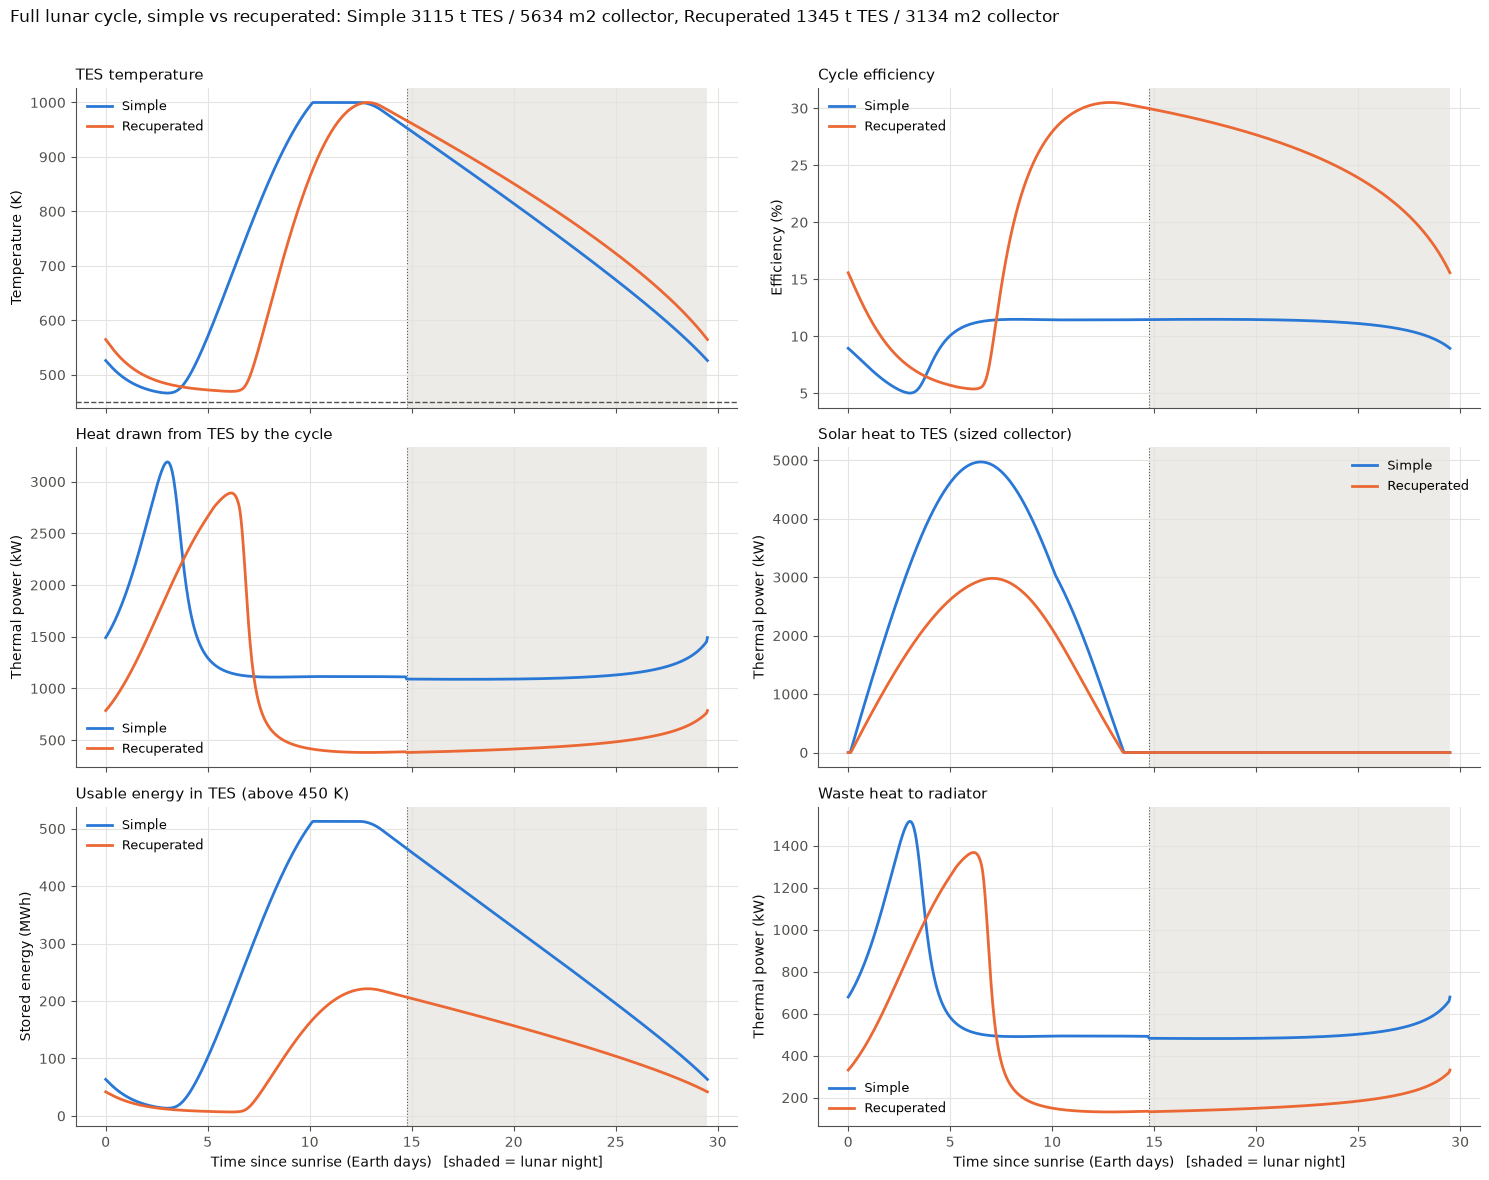

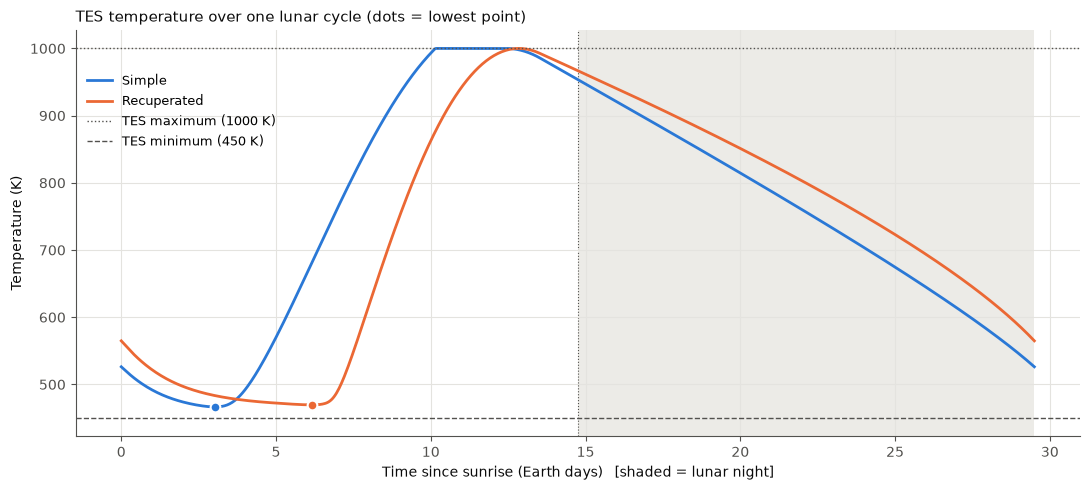

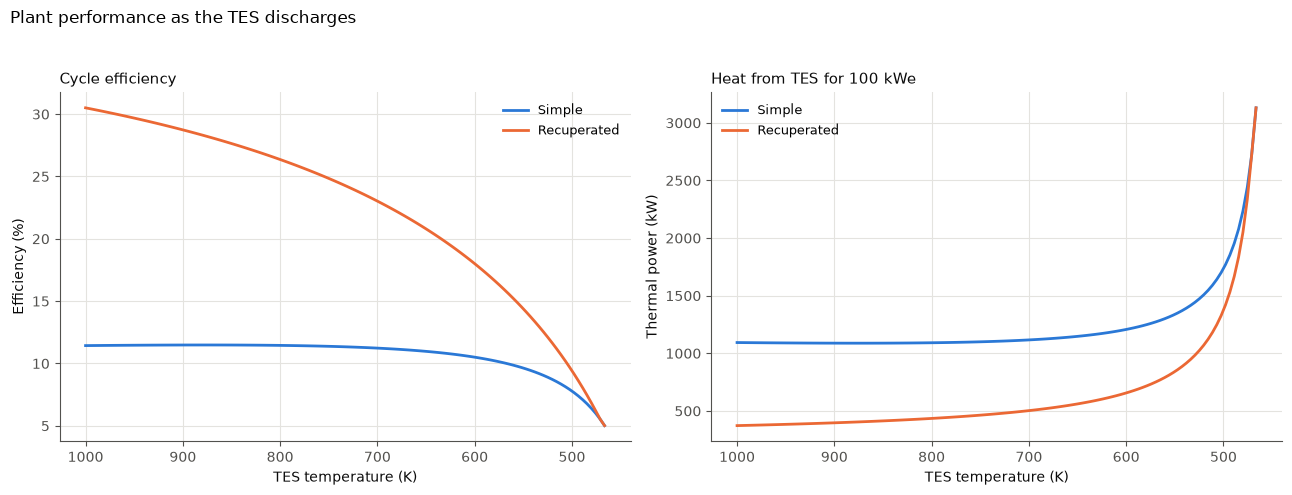

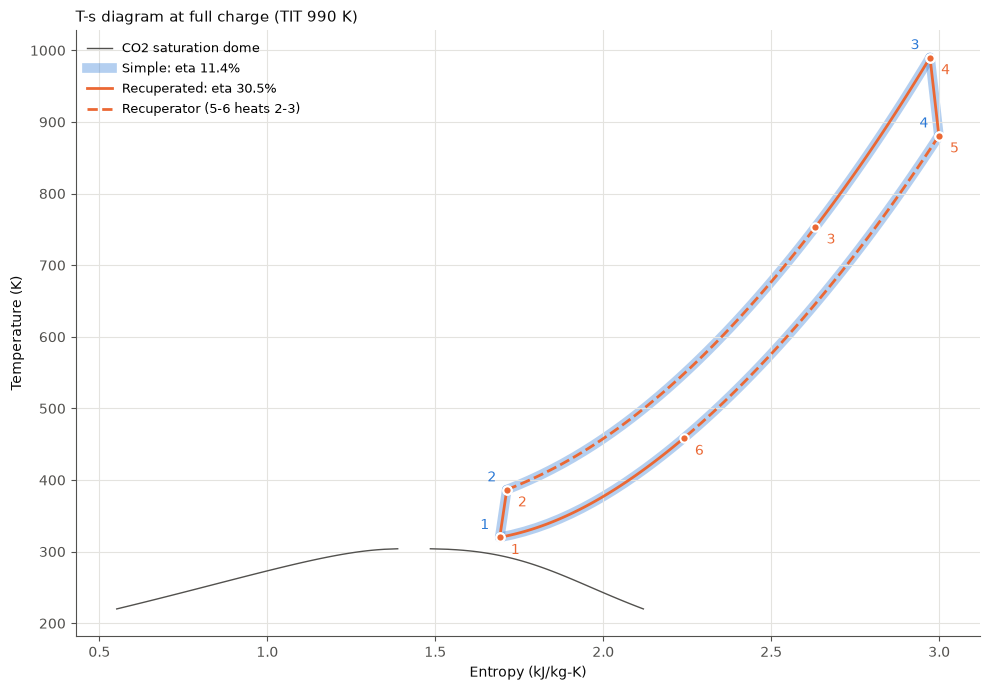

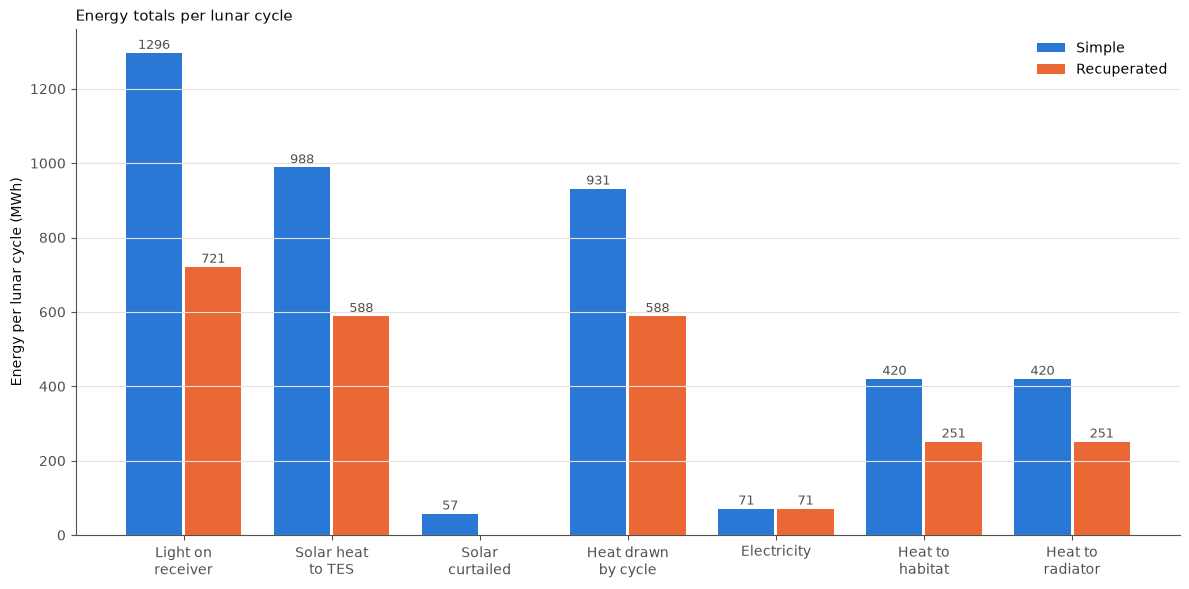

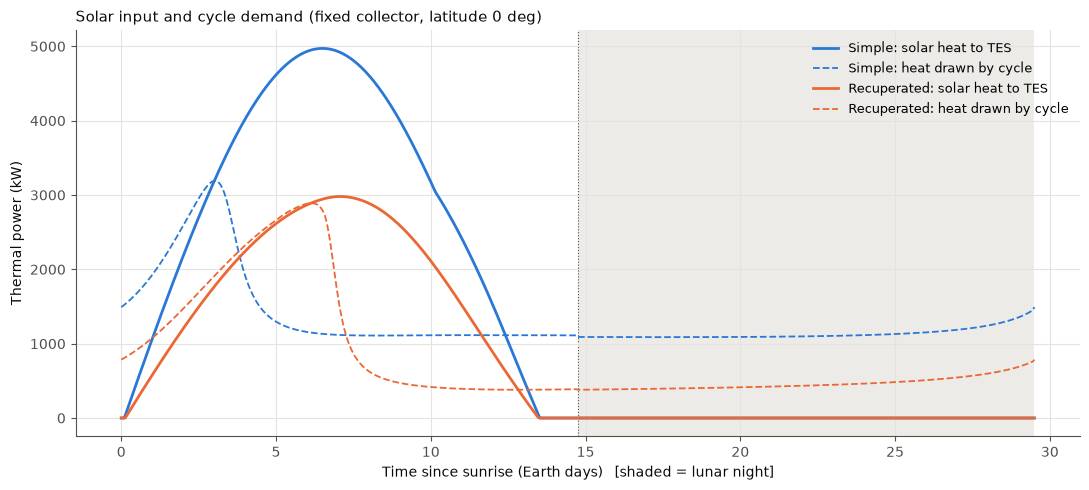

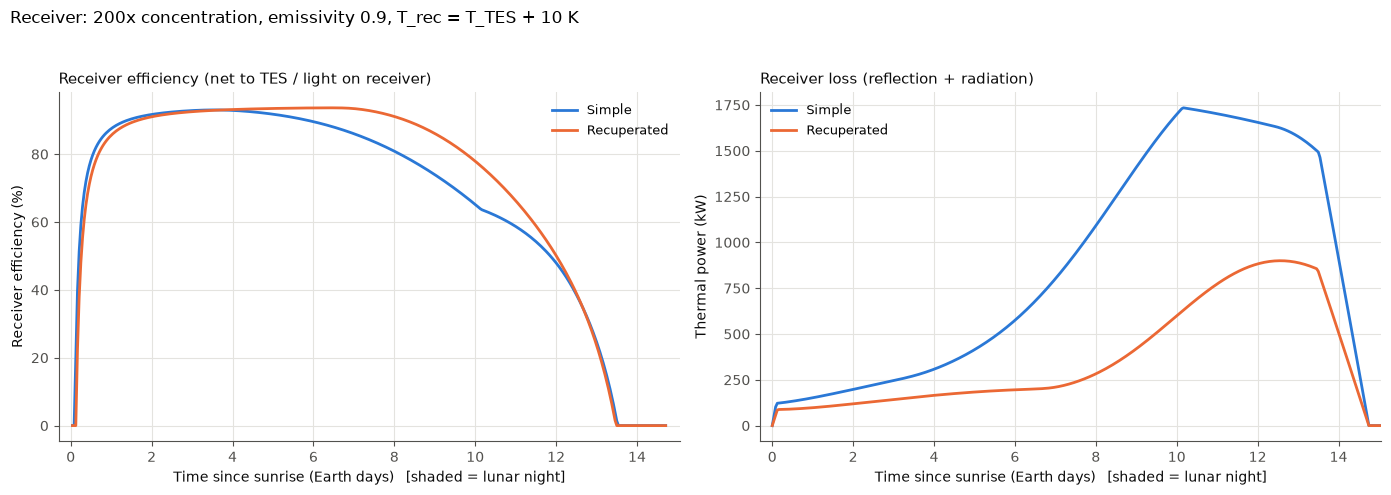

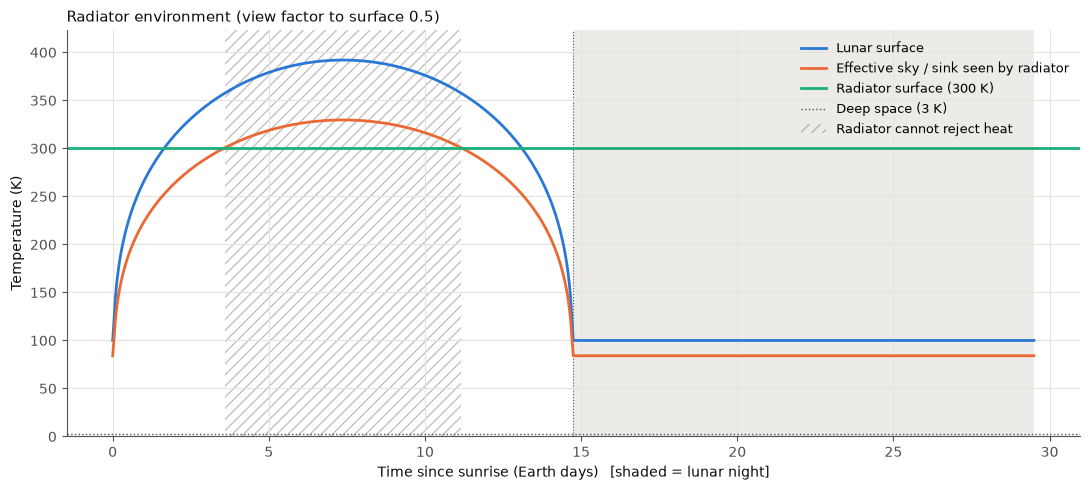

In [14]:
# =====================================================================
# Step 15: Plots, simple vs recuperated (run after Steps 1-11)
# Shows every figure and saves them to one PDF plus individual PNGs
# =====================================================================
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# --- Style: one colour per cycle, used the same way in every figure ---
COL = {'simple': '#2a78d6', 'recuperated': '#eb6834'}
LAB = {'simple': 'Simple', 'recuperated': 'Recuperated'}
C3 = '#1baf7a'
INK, INK2, GRID, NIGHT = '#0b0b0b', '#52514e', '#e4e3df', '#ecebe7'
plt.rcParams.update({
    'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
    'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'axes.titlecolor': INK,
    'xtick.color': INK2, 'ytick.color': INK2, 'axes.grid': True,
    'grid.color': GRID, 'grid.linewidth': 0.8, 'lines.linewidth': 2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'figure.dpi': 100,
})

days = R[cycles[0]]['cycle']['t'] / 24.0      # time since sunrise, Earth days
sunset_d = t_day / 24.0
XLABEL = 'Time since sunrise (Earth days)   [shaded = lunar night]'

def shade_night(ax):
    ax.axvspan(sunset_d, days[-1], color=NIGHT, zorder=0, lw=0)
    ax.axvline(sunset_d, color=INK2, lw=0.8, ls=':', zorder=1)

def style(ax, ylabel, title, xlabel=None, legend=True, loc='best'):
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc='left')
    if xlabel:
        ax.set_xlabel(xlabel)
    if legend and len(ax.get_lines()) > 1:
        ax.legend(loc=loc, fontsize=9)

def both(ax, key, scale=1.0, **kw):
    for ct in cycles:
        ax.plot(days, R[ct]['cycle'][key] * scale, color=COL[ct], label=LAB[ct], **kw)

figs = []

# ---------------------------------------------------------------------
# Figure 1: one full lunar cycle, both cycles
# ---------------------------------------------------------------------
fig, ax = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
a = ax.ravel()
both(a[0], 'T_TES');                   style(a[0], 'Temperature (K)', 'TES temperature')
a[0].axhline(T_TES_min, color=INK2, lw=1, ls='--')
both(a[1], 'eta', 100);                style(a[1], 'Efficiency (%)', 'Cycle efficiency')
both(a[2], 'Q_in');                    style(a[2], 'Thermal power (kW)', 'Heat drawn from TES by the cycle')
both(a[3], 'Q_solar');                 style(a[3], 'Thermal power (kW)', 'Solar heat to TES (sized collector)')
both(a[4], 'E_TES', 1e-3);             style(a[4], 'Stored energy (MWh)', f'Usable energy in TES (above {T_TES_min:.0f} K)', XLABEL)
both(a[5], 'Q_rad');                   style(a[5], 'Thermal power (kW)', 'Waste heat to radiator', XLABEL)
for x in a:
    shade_night(x)
fig.suptitle('Full lunar cycle, simple vs recuperated: ' +
             ', '.join(f"{LAB[ct]} {R[ct]['m_TES']/1e3:.0f} t TES / {R[ct]['A_col']:.0f} m2 collector"
                       for ct in cycles),
             x=0.01, ha='left', fontsize=12, color=INK)
fig.tight_layout(rect=[0, 0, 1, 0.97])
figs.append(('lunar_cycle', fig))

# ---------------------------------------------------------------------
# Figure 2: TES temperature over the lunar cycle
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5))
both(ax, 'T_TES')
ax.axhline(T_TES_max, color=INK2, lw=1, ls=':', label=f'TES maximum ({T_TES_max:.0f} K)')
ax.axhline(T_TES_min, color=INK2, lw=1, ls='--', label=f'TES minimum ({T_TES_min:.0f} K)')
for ct in cycles:
    T_ = R[ct]['cycle']['T_TES']; k = np.argmin(T_)
    ax.plot(days[k], T_[k], 'o', color=COL[ct], ms=7, mec='white', mew=1.5)
shade_night(ax)
style(ax, 'Temperature (K)', 'TES temperature over one lunar cycle (dots = lowest point)', XLABEL)
ax.legend(loc='upper left', bbox_to_anchor=(0.0, 0.92), fontsize=9)
fig.tight_layout()
figs.append(('TES_temperature', fig))

# ---------------------------------------------------------------------
# Figure 3: performance versus TES temperature (Section VI.4, night)
# ---------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ct in cycles:
    T_sw = np.linspace(CYC[ct]['T_TES_cutoff'], T_TES_max, 120)
    P_sw = [plant_point(T, ct=ct) for T in T_sw]
    ax[0].plot(T_sw, [p['eta'] * 100 for p in P_sw], color=COL[ct], label=LAB[ct])
    ax[1].plot(T_sw, [p['Q_in'] for p in P_sw], color=COL[ct], label=LAB[ct])
style(ax[0], 'Efficiency (%)', 'Cycle efficiency', 'TES temperature (K)')
style(ax[1], 'Thermal power (kW)', f'Heat from TES for {W_elec_target:.0f} kWe', 'TES temperature (K)')
ax[0].invert_xaxis()       # shared x: invert once; reads left to right as the TES discharges
fig.suptitle('Plant performance as the TES discharges', x=0.01, ha='left', fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.95])
figs.append(('vs_TES_temperature', fig))

# ---------------------------------------------------------------------
# Figure 4: T-s diagram at full charge, both cycles
# ---------------------------------------------------------------------
def s_of(h, P):
    return CP.PropsSI('S', 'H', h, 'P', P, FLUID) / 1e3
def T_of(h, P):
    return CP.PropsSI('T', 'H', h, 'P', P, FLUID)
def isobar(P, ha, hb, n=60):
    h = np.linspace(ha, hb, n)
    return np.array([s_of(x, P) for x in h]), np.array([T_of(x, P) for x in h])

fig, ax = plt.subplots(figsize=(10, 7))
Ts = np.linspace(220, 304.0, 120)
ax.plot([CP.PropsSI('S', 'T', T, 'Q', 0, FLUID) / 1e3 for T in Ts], Ts, color=INK2, lw=1)
ax.plot([CP.PropsSI('S', 'T', T, 'Q', 1, FLUID) / 1e3 for T in Ts], Ts, color=INK2, lw=1,
        label='CO2 saturation dome')
for ct in cycles:
    col = COL[ct]
    if ct == 'simple':
        r = simple_cycle(TIT_max)
        pts = [(r['h1'], P_low), (r['h2'], P_high), (r['h3'], P_high), (r['h4'], P_low)]
        legs = [('line', 0, 1), ('isobar', 1, 2), ('line', 2, 3), ('isobar', 3, 0)]
    else:
        r = recuperated_cycle(TIT_max)
        pts = [(r['h1'], P_low), (r['h2'], P_high), (r['h3'], P_high),
               (r['h4'], P_high), (r['h5'], P_low), (r['h6'], P_low)]
        legs = [('line', 0, 1), ('isobar', 1, 2), ('isobar', 2, 3), ('line', 3, 4),
                ('isobar', 4, 5), ('isobar', 5, 0)]
    # simple: wide translucent band underneath; recuperated: thin line on top,
    # with the two recuperator legs (2-3 cold side, 5-6 hot side) dashed
    lw, alpha, z = (7, 0.35, 1) if ct == 'simple' else (2, 1.0, 3)
    recup_legs = {(1, 2), (4, 5)} if ct == 'recuperated' else set()
    for kind, i, j in legs:
        (hi, Pi), (hj, Pj) = pts[i], pts[j]
        ls = '--' if (i, j) in recup_legs else '-'
        if kind == 'line':
            ax.plot([s_of(hi, Pi), s_of(hj, Pj)], [T_of(hi, Pi), T_of(hj, Pj)],
                    color=col, lw=lw, alpha=alpha, ls=ls, zorder=z, solid_capstyle='round')
        else:
            x, y = isobar(Pi, hi, hj)
            ax.plot(x, y, color=col, lw=lw, alpha=alpha, ls=ls, zorder=z, solid_capstyle='round')
    ax.plot([], [], color=col, lw=lw if ct == 'simple' else 2, alpha=alpha,
            label=f"{LAB[ct]}: eta {r['eta']*100:.1f}%")
    if ct == 'recuperated':
        ax.plot([], [], color=col, ls='--', label='Recuperator (5-6 heats 2-3)')
    for n, (h, P) in enumerate(pts, 1):
        ax.plot(s_of(h, P), T_of(h, P), 'o', color=col, ms=6, mec='white', mew=1.5, zorder=4)
        ax.annotate(str(n), (s_of(h, P), T_of(h, P)), textcoords='offset points',
                    xytext=(8, -12) if ct == 'recuperated' else (-14, 6), color=col, zorder=5)
style(ax, 'Temperature (K)', f'T-s diagram at full charge (TIT {TIT_max:.0f} K)', 'Entropy (kJ/kg-K)',
      legend=False)
ax.legend(loc='upper left', fontsize=9)
fig.tight_layout()
figs.append(('Ts_diagram', fig))

# ---------------------------------------------------------------------
# Figure 5: energy totals per lunar cycle, both cycles
# ---------------------------------------------------------------------
items = [('Q_sun_in', 'Light on\nreceiver'), ('Q_solar', 'Solar heat\nto TES'), ('Q_curtail', 'Solar\ncurtailed'),
         ('Q_in', 'Heat drawn\nby cycle'), ('W_elec', 'Electricity'),
         ('Q_hab', 'Heat to\nhabitat'), ('Q_rad', 'Heat to\nradiator')]
tot = lambda d, k: np.sum(d[k][:-1]) * dt / 1e3
x = np.arange(len(items)); w = 0.38
fig, ax = plt.subplots(figsize=(12, 6))
for i, ct in enumerate(cycles):
    off = (-1 if i == 0 else 1) * (w / 2 + 0.01)
    bars = ax.bar(x + off, [tot(R[ct]['cycle'], k) for k, _ in items], w, color=COL[ct], label=LAB[ct])
    for b in bars:
        if b.get_height() > 0.05:
            ax.annotate(f'{b.get_height():.0f}', (b.get_x() + b.get_width()/2, b.get_height()),
                        textcoords='offset points', xytext=(0, 3), ha='center', fontsize=9, color=INK2)
ax.set_xticks(x, [lbl for _, lbl in items])
ax.grid(axis='x', visible=False)
style(ax, 'Energy per lunar cycle (MWh)', 'Energy totals per lunar cycle', legend=False)
ax.legend()
fig.tight_layout()
figs.append(('energy_totals', fig))

# ---------------------------------------------------------------------
# Figure 6: solar input vs cycle demand
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5))
for ct in cycles:
    ax.plot(days, R[ct]['cycle']['Q_solar'], color=COL[ct], label=f"{LAB[ct]}: solar heat to TES")
    ax.plot(days, R[ct]['cycle']['Q_in'], color=COL[ct], lw=1.3, ls='--', label=f"{LAB[ct]}: heat drawn by cycle")
shade_night(ax)
style(ax, 'Thermal power (kW)', f'Solar input and cycle demand ({collector_mode} collector, '
      f'latitude {latitude_deg:.0f} deg)', XLABEL)
fig.tight_layout()
figs.append(('solar_input', fig))

# ---------------------------------------------------------------------
# Figure 6b: receiver efficiency and loss through the lunar day
# ---------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ct in cycles:
    cy = R[ct]['cycle']
    ax[0].plot(days, cy['eta_rec_t'] * 100, color=COL[ct], label=LAB[ct])
    ax[1].plot(days, cy['Q_rec_loss'], color=COL[ct], label=LAB[ct])
style(ax[0], 'Receiver efficiency (%)', 'Receiver efficiency (net to TES / light on receiver)', XLABEL)
style(ax[1], 'Thermal power (kW)', 'Receiver loss (reflection + radiation)', XLABEL)
ax[0].set_xlim(-0.3, sunset_d + 0.3)
fig.suptitle(f'Receiver: {C_ratio:.0f}x concentration, emissivity {eps_rec}, '
             f'T_rec = T_TES + {dT_rec:.0f} K', x=0.01, ha='left', fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.95])
figs.append(('receiver', fig))

# ---------------------------------------------------------------------
# Figure 7: radiator environment (sky / sink temperature)
# ---------------------------------------------------------------------
_cy = R[cycles[0]]['cycle']
no_reject = _cy['T_sink'] >= T_rad
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(days, T_surface(_cy['t']), color='#2a78d6', label='Lunar surface')
ax.plot(days, _cy['T_sink'], color='#eb6834', label='Effective sky / sink seen by radiator')
ax.axhline(T_rad, color=C3, lw=2, label=f'Radiator surface ({T_rad:.0f} K)')
ax.axhline(T_space, color=INK2, lw=1, ls=':', label=f'Deep space ({T_space:.0f} K)')
ax.fill_between(days, 0, 1, where=no_reject, transform=ax.get_xaxis_transform(),
                facecolor='none', edgecolor=INK2, hatch='///', lw=0, alpha=0.35,
                label='Radiator cannot reject heat')
shade_night(ax)
style(ax, 'Temperature (K)',
      f"Radiator environment ({'shielded' if shield else f'view factor to surface {F_rad_surf}'})",
      XLABEL, legend=False)
ax.legend(loc='upper right', fontsize=9)
ax.set_ylim(0, max(T_surf_noon, T_rad) * 1.08)
fig.tight_layout()
figs.append(('radiator_environment', fig))